In [11]:
%pip install -U qiskit qiskit-ibm-runtime matplotlib

Note: you may need to restart the kernel to use updated packages.


In [12]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

print("IBM account connected!")

backends = service.backends(simulator=False, operational=True)
print("Available real quantum backends:", len(backends))

for backend in backends:
    print(backend.name, "| Qubits:", backend.num_qubits)

IBM account connected!
Available real quantum backends: 3
ibm_fez | Qubits: 156
ibm_kingston | Qubits: 156
ibm_marrakesh | Qubits: 156


Circuit_A


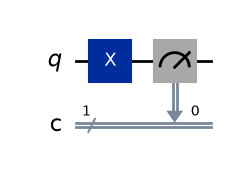

Circuit_B


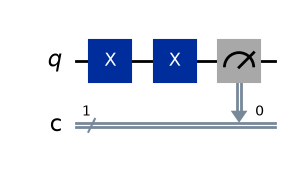

Circuit_C


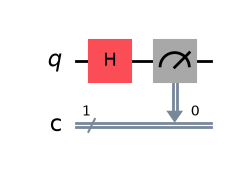

All three circuits are ready!


In [13]:
from qiskit import QuantumCircuit
from IPython.display import display

# Circuit A: One X gate
circuit_a = QuantumCircuit(1, 1, name="Circuit_A")
circuit_a.x(0)
circuit_a.measure(0, 0)

# Circuit B: Two X gates
circuit_b = QuantumCircuit(1, 1, name="Circuit_B")
circuit_b.x(0)
circuit_b.x(0)
circuit_b.measure(0, 0)

# Circuit C: One H gate
circuit_c = QuantumCircuit(1, 1, name="Circuit_C")
circuit_c.h(0)
circuit_c.measure(0, 0)

# Store all three circuits in a list
circuits = [circuit_a, circuit_b, circuit_c]

for circuit in circuits:
    print(circuit.name)
    display(circuit.draw("mpl"))

print("All three circuits are ready!")

In [15]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

print("IBM account connected successfully!")

IBM account connected successfully!


In [17]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

for item in service.jobs(limit=10):
    print("Job ID:", item.job_id())
    print("Status:", item.status())
    print("-" * 40)

Job ID: db50n5imb58s7389rg3g
Status: DONE
----------------------------------------
Job ID: db50mvamb58s7389rfrg
Status: DONE
----------------------------------------
Job ID: db50c684qg6s73c2q96g
Status: DONE
----------------------------------------
Job ID: db50c2klf4us73c3cdng
Status: DONE
----------------------------------------
Job ID: db50bkkvf2bc73cv7u4g
Status: DONE
----------------------------------------
Job ID: db505nimb58s7389qpjg
Status: DONE
----------------------------------------
Job ID: db5014svf2bc73cv7hig
Status: DONE
----------------------------------------
Job ID: db500rslf4us73c3bvmg
Status: DONE
----------------------------------------
Job ID: db500mslf4us73c3bvdg
Status: DONE
----------------------------------------
Job ID: db500jclf4us73c3bv6g
Status: DONE
----------------------------------------


In [18]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

job = service.job("db50n5imb58s7389rg3g")

print("Job ID:", job.job_id())
print("Status:", job.status())
print("Backend:", job.backend().name)

Job ID: db50n5imb58s7389rg3g
Status: DONE
Backend: ibm_fez


Circuit 1


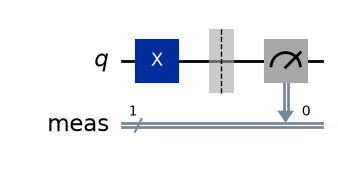

Circuit 2


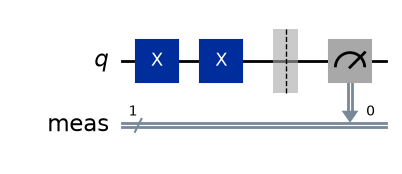

Circuit 3


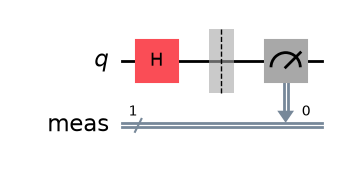

C:\Users\Syam_Vadarevula\AppData\Local\Temp\ipykernel_15968\1332465165.py:41: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Job submitted!
Backend: ibm_fez
Job ID: db5rdqcvf2bc73d0alh0
Status: RUNNING


In [22]:
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from IPython.display import display

# Connect to IBM Quantum
service = QiskitRuntimeService()
backend = service.backend("ibm_fez")

# Circuit A: One X gate
circuit_a = QuantumCircuit(1)
circuit_a.x(0)
circuit_a.measure_all()

# Circuit B: Two X gates
circuit_b = QuantumCircuit(1)
circuit_b.x(0)
circuit_b.x(0)
circuit_b.measure_all()

# Circuit C: One H gate
circuit_c = QuantumCircuit(1)
circuit_c.h(0)
circuit_c.measure_all()

circuits = [circuit_a, circuit_b, circuit_c]

# Display the circuits
for i, circuit in enumerate(circuits, start=1):
    print(f"Circuit {i}")
    display(circuit.draw("mpl"))

# Compile circuits for real IBM hardware
pass_manager = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)
isa_circuits = pass_manager.run(circuits)

# Submit one job containing three circuits, 100 shots each
sampler = Sampler(mode=backend)
job = sampler.run(isa_circuits, shots=100)

print("Job submitted!")
print("Backend:", backend.name)
print("Job ID:", job.job_id())
print("Status:", job.status())

In [23]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()
job = service.job("db5rdqcvf2bc73d0alh0")

print("Job status:", job.status())

if str(job.status()) == "DONE":
    result = job.result()

    counts_a = result[0].data.meas.get_counts()
    counts_b = result[1].data.meas.get_counts()
    counts_c = result[2].data.meas.get_counts()

    print("Circuit A:", counts_a)
    print("Circuit B:", counts_b)
    print("Circuit C:", counts_c)
else:
    print("Job is not finished yet. Run this cell again later.")

Job status: DONE
Circuit A: {'1': 96, '0': 4}
Circuit B: {'0': 100}
Circuit C: {'1': 40, '0': 60}


In [27]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

plot_histogram(counts_a, title="Circuit A: One X Gate — IBM Hardware")
plt.show()

plot_histogram(counts_b, title="Circuit B: Two X Gates — IBM Hardware")
plt.show()

plot_histogram(counts_c, title="Circuit C: One H Gate — IBM Hardware")
plt.show()

In [30]:
from IPython.display import display, Markdown

report = r"""
# Qiskit Fall Fest 2026
## Challenge 1: Predict the Output

### 1. Objective
To predict the measurement outcomes of three single-qubit quantum circuits, execute them on real IBM quantum hardware, and compare predictions with actual results.

### 2. Circuit A — One X Gate
**Prediction:** The X gate flips |0> to |1>. Ideally, every measurement returns 1.

**Actual results (100 shots):**
- 1: 96
- 0: 4

**Observation:** 96% of measurements returned 1. The remaining outcomes may be due to hardware noise.

### 3. Circuit B — Two X Gates
**Prediction:** Two X gates return the qubit to |0>.

**Actual results (100 shots):**
- 0: 100
- 1: 0

**Observation:** All measurements returned 0, matching the ideal prediction.

### 4. Circuit C — One H Gate
**Prediction:** The Hadamard gate creates an equal superposition of |0> and |1>, giving each outcome a probability of 50%.

**Actual results (100 shots):**
- 0: 60
- 1: 40

**Observation:** Both outcomes occurred, with 60% measured as 0 and 40% as 1.

### 5. Final Comparison

| Circuit | Expected result | Actual result |
|---|---|---|
| A — One X gate | 100% 1 ideally | 96% 1, 4% 0 |
| B — Two X gates | 100% 0 ideally | 100% 0 |
| C — One H gate | Approximately 50% each | 60% 0, 40% 1 |

### 6. Conclusion
The experiment demonstrated how quantum gates affect measurement outcomes. One X gate flips the qubit, two X gates return it to its initial state, and an H gate produces probabilistic outcomes.

**IBM backend:** ibm_fez  
**IBM Job ID:** db5rdqcvf2bc73d0alh0  
**Shots per circuit:** 100
"""

display(Markdown(report))


# Qiskit Fall Fest 2026
## Challenge 1: Predict the Output

### 1. Objective
To predict the measurement outcomes of three single-qubit quantum circuits, execute them on real IBM quantum hardware, and compare predictions with actual results.

### 2. Circuit A — One X Gate
**Prediction:** The X gate flips |0> to |1>. Ideally, every measurement returns 1.

**Actual results (100 shots):**
- 1: 96
- 0: 4

**Observation:** 96% of measurements returned 1. The remaining outcomes may be due to hardware noise.

### 3. Circuit B — Two X Gates
**Prediction:** Two X gates return the qubit to |0>.

**Actual results (100 shots):**
- 0: 100
- 1: 0

**Observation:** All measurements returned 0, matching the ideal prediction.

### 4. Circuit C — One H Gate
**Prediction:** The Hadamard gate creates an equal superposition of |0> and |1>, giving each outcome a probability of 50%.

**Actual results (100 shots):**
- 0: 60
- 1: 40

**Observation:** Both outcomes occurred, with 60% measured as 0 and 40% as 1.

### 5. Final Comparison

| Circuit | Expected result | Actual result |
|---|---|---|
| A — One X gate | 100% 1 ideally | 96% 1, 4% 0 |
| B — Two X gates | 100% 0 ideally | 100% 0 |
| C — One H gate | Approximately 50% each | 60% 0, 40% 1 |

### 6. Conclusion
The experiment demonstrated how quantum gates affect measurement outcomes. One X gate flips the qubit, two X gates return it to its initial state, and an H gate produces probabilistic outcomes.

**IBM backend:** ibm_fez  
**IBM Job ID:** db5rdqcvf2bc73d0alh0  
**Shots per circuit:** 100
